# Week 4 — Full reconstruction validation

This notebook analyses the full frozen experiment across six elephants,
77 continuous trajectory segments, 30-, 60-, 120- and 240-minute sampling
schedules, all valid starting offsets, and the linear, cubic and PCHIP
interpolation methods.

Headline comparisons use the common eligible validation population.
The mandatory criteria were frozen before the full results were viewed:

- median position error no greater than 100 metres; and
- median absolute path-length error no greater than 10%.

Both criteria must pass.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml


current_folder = Path.cwd()

if (
    (current_folder / "data").is_dir()
    and (current_folder / "src").is_dir()
):
    PROJECT_FOLDER = current_folder

elif (
    (current_folder.parent / "data").is_dir()
    and (current_folder.parent / "src").is_dir()
):
    PROJECT_FOLDER = current_folder.parent

else:
    raise FileNotFoundError(
        "Could not find the MMA3001 project folder."
    )


if str(PROJECT_FOLDER) not in sys.path:
    sys.path.insert(
        0,
        str(PROJECT_FOLDER),
    )


from src import reconstruction


DATA_FOLDER = (
    PROJECT_FOLDER
    / "data"
    / "processed"
)

PREDICTION_FOLDER = (
    DATA_FOLDER
    / "week4_predictions"
)

REPORTS_FOLDER = (
    PROJECT_FOLDER
    / "reports"
)

FIGURES_FOLDER = (
    PROJECT_FOLDER
    / "figures"
)

PRIVATE_FIGURES_FOLDER = (
    PROJECT_FOLDER
    / "private_figures"
)

CONTRACT_FILE = (
    REPORTS_FOLDER
    / "experiment_contract.yaml"
)

REFERENCE_FILE = (
    DATA_FOLDER
    / "elephant_gps_cleaned_reference.csv"
)


FIGURES_FOLDER.mkdir(
    parents=True,
    exist_ok=True,
)

PRIVATE_FIGURES_FOLDER.mkdir(
    parents=True,
    exist_ok=True,
)


POSITION_TOLERANCE_M = 100.0
PATH_TOLERANCE_PERCENT = 10.0

sns.set_theme(style="whitegrid")

pd.set_option(
    "display.max_columns",
    50,
)


print("Project folder:", PROJECT_FOLDER)
print("Python:", sys.executable)

Project folder: c:\Users\kookie\OneDrive\MMA3001_project
Python: c:\Users\kookie\OneDrive\MMA3001_project\.venv\Scripts\python.exe


In [2]:
reference = reconstruction.load_reference(
    REFERENCE_FILE
)

support = pd.read_csv(
    REPORTS_FOLDER
    / "week4_support_audit.csv"
)

common_cases = pd.read_csv(
    REPORTS_FOLDER
    / "week4_common_eligible_cases.csv"
)

coverage = pd.read_csv(
    REPORTS_FOLDER
    / "week4_method_coverage.csv"
)

cases = pd.read_csv(
    REPORTS_FOLDER
    / "week4_case_results.csv"
)

validation_summary = pd.read_csv(
    REPORTS_FOLDER
    / "week4_validation_summary.csv"
)

per_animal = pd.read_csv(
    REPORTS_FOLDER
    / "week4_per_animal_summary.csv"
)

per_offset = pd.read_csv(
    REPORTS_FOLDER
    / "week4_offset_summary.csv"
)

decision_table = pd.read_csv(
    REPORTS_FOLDER
    / "week4_decision_table.csv"
)

worst_points = pd.read_csv(
    REPORTS_FOLDER
    / "week4_worst_points.csv"
)

with (
    REPORTS_FOLDER
    / "week4_experiment_manifest.json"
).open(
    "r",
    encoding="utf-8",
) as stream:
    manifest = json.load(stream)


method_order = [
    method
    for method in [
        "linear",
        "cubic",
        "pchip",
    ]
    if method
    in decision_table["Method"].unique()
]

interval_order = sorted(
    decision_table[
        "Interval_min"
    ].unique()
)


print("Cleaned fixes:", len(reference))
print(
    "Animals:",
    reference["AnimalID"].nunique(),
)
print(
    "Segments:",
    reference["SegmentID"].nunique(),
)
print(
    "Support-audit rows:",
    len(support),
)
print(
    "Common cases:",
    len(common_cases),
)
print(
    "Method-case runs:",
    len(cases),
)
print(
    "Methods:",
    method_order,
)
print(
    "Intervals:",
    interval_order,
)

Cleaned fixes: 59994
Animals: 6
Segments: 77
Support-audit rows: 6930
Common cases: 2138
Method-case runs: 6414
Methods: ['linear', 'cubic', 'pchip']
Intervals: [np.int64(30), np.int64(60), np.int64(120), np.int64(240)]


In [3]:
prediction_files = sorted(
    list(
        PREDICTION_FOLDER.glob(
            "*.parquet"
        )
    )
    + list(
        PREDICTION_FOLDER.glob(
            "*.csv.gz"
        )
    )
)


checks = {
    "cleaned_rows": len(reference),
    "animal_count": (
        reference["AnimalID"].nunique()
    ),
    "segment_count": (
        reference["SegmentID"].nunique()
    ),
    "support_audit_rows": len(support),
    "common_case_count": len(common_cases),
    "method_case_runs": len(cases),
    "prediction_partitions": (
        len(prediction_files)
    ),
    "unexpected_failed_cases": int(
        (~cases["Status"].eq("ok")).sum()
    ),
}


display(
    pd.DataFrame.from_dict(
        checks,
        orient="index",
        columns=["Observed value"],
    )
)


assert checks["cleaned_rows"] == 59_994
assert checks["animal_count"] == 6
assert checks["segment_count"] == 77
assert checks["support_audit_rows"] == 6_930
assert checks["common_case_count"] == 2_138
assert checks["method_case_runs"] == 6_414
assert checks["prediction_partitions"] == 12
assert checks["unexpected_failed_cases"] == 0

print("WEEK 4 FULL-RUN STRUCTURE: PASS")

,Observed value
cleaned_rows,59994
animal_count,6
segment_count,77
support_audit_rows,6930
common_case_count,2138
method_case_runs,6414
prediction_partitions,12
unexpected_failed_cases,0


WEEK 4 FULL-RUN STRUCTURE: PASS


In [4]:
decision_columns = [
    "Method",
    "Interval_min",
    "PredictedFixes",
    "MedianPositionError_m",
    "MAE_m",
    "RMSE_m",
    "P95PositionError_m",
    "MedianSignedPathError_percent",
    "MedianAbsolutePathError_percent",
    "MedianFixReduction_percent",
    "OvershootPercent",
    "CaseCoverage_percent",
    "TotalInterpolationRuntime_s",
    "MandatoryCriteriaPass",
    "AnimalsPassingBoth",
    "AnimalsEvaluated",
    "AllAnimalsPass",
]


decision_view = (
    decision_table[
        decision_columns
    ]
    .sort_values(
        [
            "Interval_min",
            "Method",
        ]
    )
    .reset_index(drop=True)
)


display(
    decision_view.round(3)
)

,Method,Interval_min,PredictedFixes,MedianPositionError_m,MAE_m,RMSE_m,P95PositionError_m,MedianSignedPathError_percent,MedianAbsolutePathError_percent,MedianFixReduction_percent,OvershootPercent,CaseCoverage_percent,TotalInterpolationRuntime_s,MandatoryCriteriaPass,AnimalsPassingBoth,AnimalsEvaluated,AllAnimalsPass
0,cubic,30,59833,42.615,59.162,86.768,160.256,-5.275,5.275,49.894,32.696,94.805,0.094,True,6,6,True
1,linear,30,59833,40.786,58.571,87.378,166.767,-8.180,8.180,49.894,0.000,97.403,0.016,True,6,6,True
2,pchip,30,59833,39.632,56.445,84.318,158.135,-7.907,7.907,49.894,0.000,97.403,0.105,True,6,6,True
3,cubic,60,179061,66.822,92.526,130.662,254.985,-11.804,11.804,74.840,33.560,94.805,0.177,False,0,6,False
4,linear,60,179061,65.466,93.203,134.338,266.821,-15.774,15.774,74.840,0.000,95.779,0.034,False,0,6,False
5,pchip,60,179061,61.488,88.588,128.930,255.566,-15.168,15.168,74.840,0.000,95.779,0.199,False,0,6,False
6,cubic,120,415695,114.123,158.951,222.197,444.349,-18.779,18.779,87.319,34.693,93.506,0.348,False,0,6,False
7,linear,120,415695,114.256,162.232,230.551,466.480,-23.375,23.375,87.319,0.000,94.805,0.068,False,0,6,False
8,pchip,120,415695,105.190,152.626,220.159,446.516,-22.582,22.582,87.319,0.000,94.805,0.379,False,0,6,False
9,cubic,240,881340,216.510,294.844,403.623,806.231,-26.809,26.809,93.561,36.333,91.234,0.635,False,0,6,False


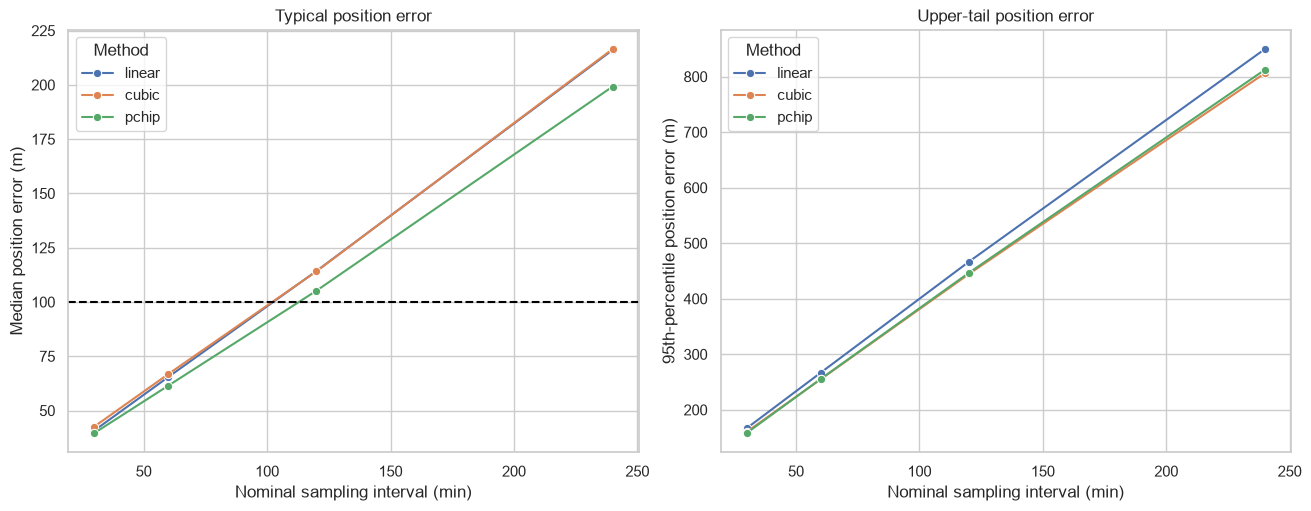

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week4_01_position_error_by_interval.png


In [5]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    constrained_layout=True,
)


sns.lineplot(
    data=decision_table,
    x="Interval_min",
    y="MedianPositionError_m",
    hue="Method",
    hue_order=method_order,
    marker="o",
    ax=axes[0],
)

axes[0].axhline(
    POSITION_TOLERANCE_M,
    color="black",
    linestyle="--",
)

axes[0].set(
    title="Typical position error",
    xlabel="Nominal sampling interval (min)",
    ylabel="Median position error (m)",
)


sns.lineplot(
    data=decision_table,
    x="Interval_min",
    y="P95PositionError_m",
    hue="Method",
    hue_order=method_order,
    marker="o",
    ax=axes[1],
)

axes[1].set(
    title="Upper-tail position error",
    xlabel="Nominal sampling interval (min)",
    ylabel="95th-percentile position error (m)",
)


figure_path = (
    FIGURES_FOLDER
    / "week4_01_position_error_by_interval.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

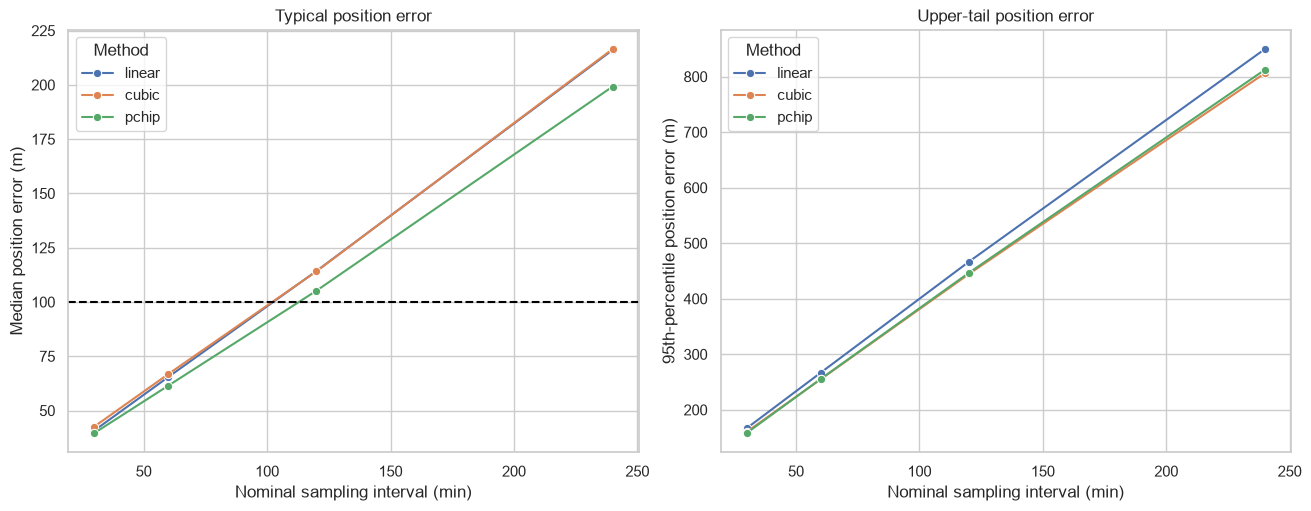

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week4_01_position_error_by_interval.png


In [6]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    constrained_layout=True,
)


sns.lineplot(
    data=decision_table,
    x="Interval_min",
    y="MedianPositionError_m",
    hue="Method",
    hue_order=method_order,
    marker="o",
    ax=axes[0],
)

axes[0].axhline(
    POSITION_TOLERANCE_M,
    color="black",
    linestyle="--",
)

axes[0].set(
    title="Typical position error",
    xlabel="Nominal sampling interval (min)",
    ylabel="Median position error (m)",
)


sns.lineplot(
    data=decision_table,
    x="Interval_min",
    y="P95PositionError_m",
    hue="Method",
    hue_order=method_order,
    marker="o",
    ax=axes[1],
)

axes[1].set(
    title="Upper-tail position error",
    xlabel="Nominal sampling interval (min)",
    ylabel="95th-percentile position error (m)",
)


figure_path = (
    FIGURES_FOLDER
    / "week4_01_position_error_by_interval.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

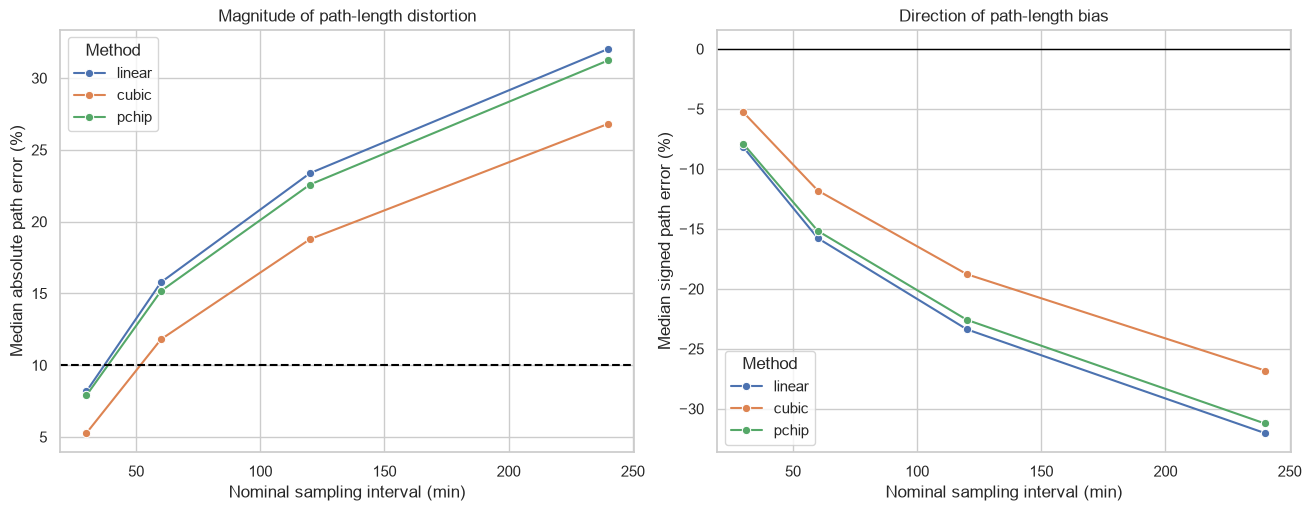

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week4_02_path_error_by_interval.png


In [7]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),
    constrained_layout=True,
)


sns.lineplot(
    data=decision_table,
    x="Interval_min",
    y="MedianAbsolutePathError_percent",
    hue="Method",
    hue_order=method_order,
    marker="o",
    ax=axes[0],
)

axes[0].axhline(
    PATH_TOLERANCE_PERCENT,
    color="black",
    linestyle="--",
)

axes[0].set(
    title="Magnitude of path-length distortion",
    xlabel="Nominal sampling interval (min)",
    ylabel="Median absolute path error (%)",
)


sns.lineplot(
    data=decision_table,
    x="Interval_min",
    y="MedianSignedPathError_percent",
    hue="Method",
    hue_order=method_order,
    marker="o",
    ax=axes[1],
)

axes[1].axhline(
    0.0,
    color="black",
    linewidth=1,
)

axes[1].set(
    title="Direction of path-length bias",
    xlabel="Nominal sampling interval (min)",
    ylabel="Median signed path error (%)",
)


figure_path = (
    FIGURES_FOLDER
    / "week4_02_path_error_by_interval.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

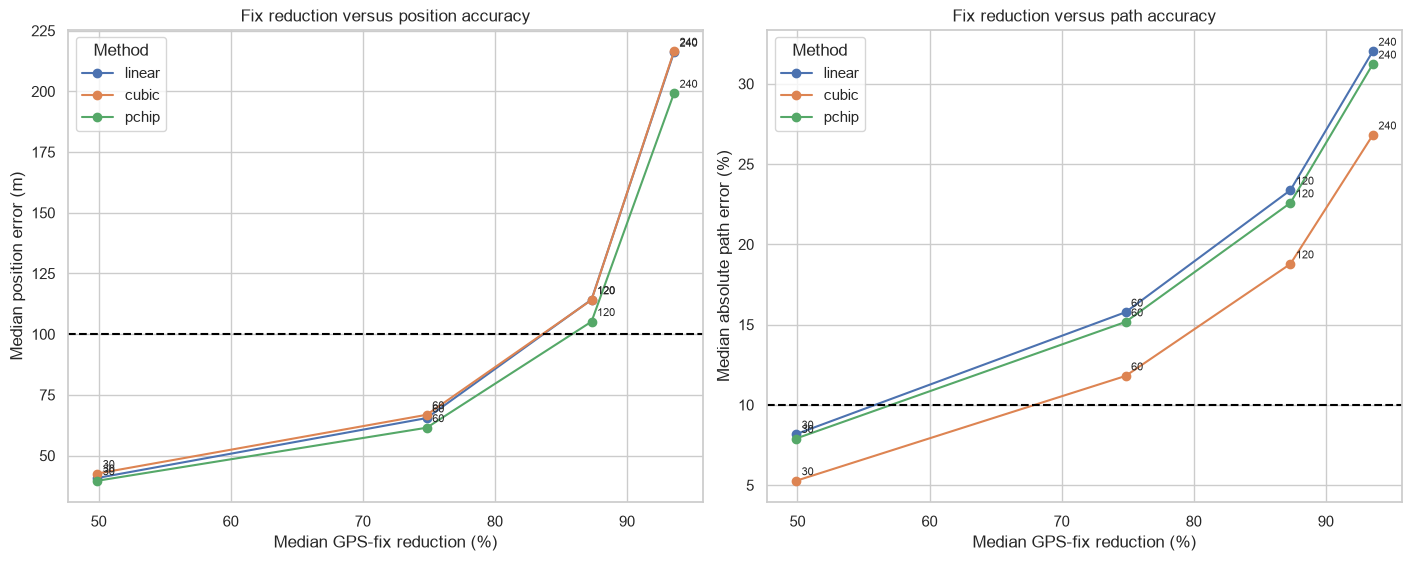

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week4_03_fix_reduction_tradeoff.png


In [8]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.5),
    constrained_layout=True,
)


for method in method_order:
    method_data = (
        decision_table.loc[
            decision_table[
                "Method"
            ].eq(method)
        ]
        .sort_values(
            "Interval_min"
        )
    )

    axes[0].plot(
        method_data[
            "MedianFixReduction_percent"
        ],
        method_data[
            "MedianPositionError_m"
        ],
        marker="o",
        label=method,
    )

    axes[1].plot(
        method_data[
            "MedianFixReduction_percent"
        ],
        method_data[
            "MedianAbsolutePathError_percent"
        ],
        marker="o",
        label=method,
    )

    for row in method_data.itertuples(
        index=False
    ):
        axes[0].annotate(
            f"{int(row.Interval_min)}",
            (
                row.MedianFixReduction_percent,
                row.MedianPositionError_m,
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

        axes[1].annotate(
            f"{int(row.Interval_min)}",
            (
                row.MedianFixReduction_percent,
                row.MedianAbsolutePathError_percent,
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )


axes[0].axhline(
    POSITION_TOLERANCE_M,
    color="black",
    linestyle="--",
)

axes[1].axhline(
    PATH_TOLERANCE_PERCENT,
    color="black",
    linestyle="--",
)


axes[0].set(
    title="Fix reduction versus position accuracy",
    xlabel="Median GPS-fix reduction (%)",
    ylabel="Median position error (m)",
)

axes[1].set(
    title="Fix reduction versus path accuracy",
    xlabel="Median GPS-fix reduction (%)",
    ylabel="Median absolute path error (%)",
)

axes[0].legend(title="Method")
axes[1].legend(title="Method")


figure_path = (
    FIGURES_FOLDER
    / "week4_03_fix_reduction_tradeoff.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

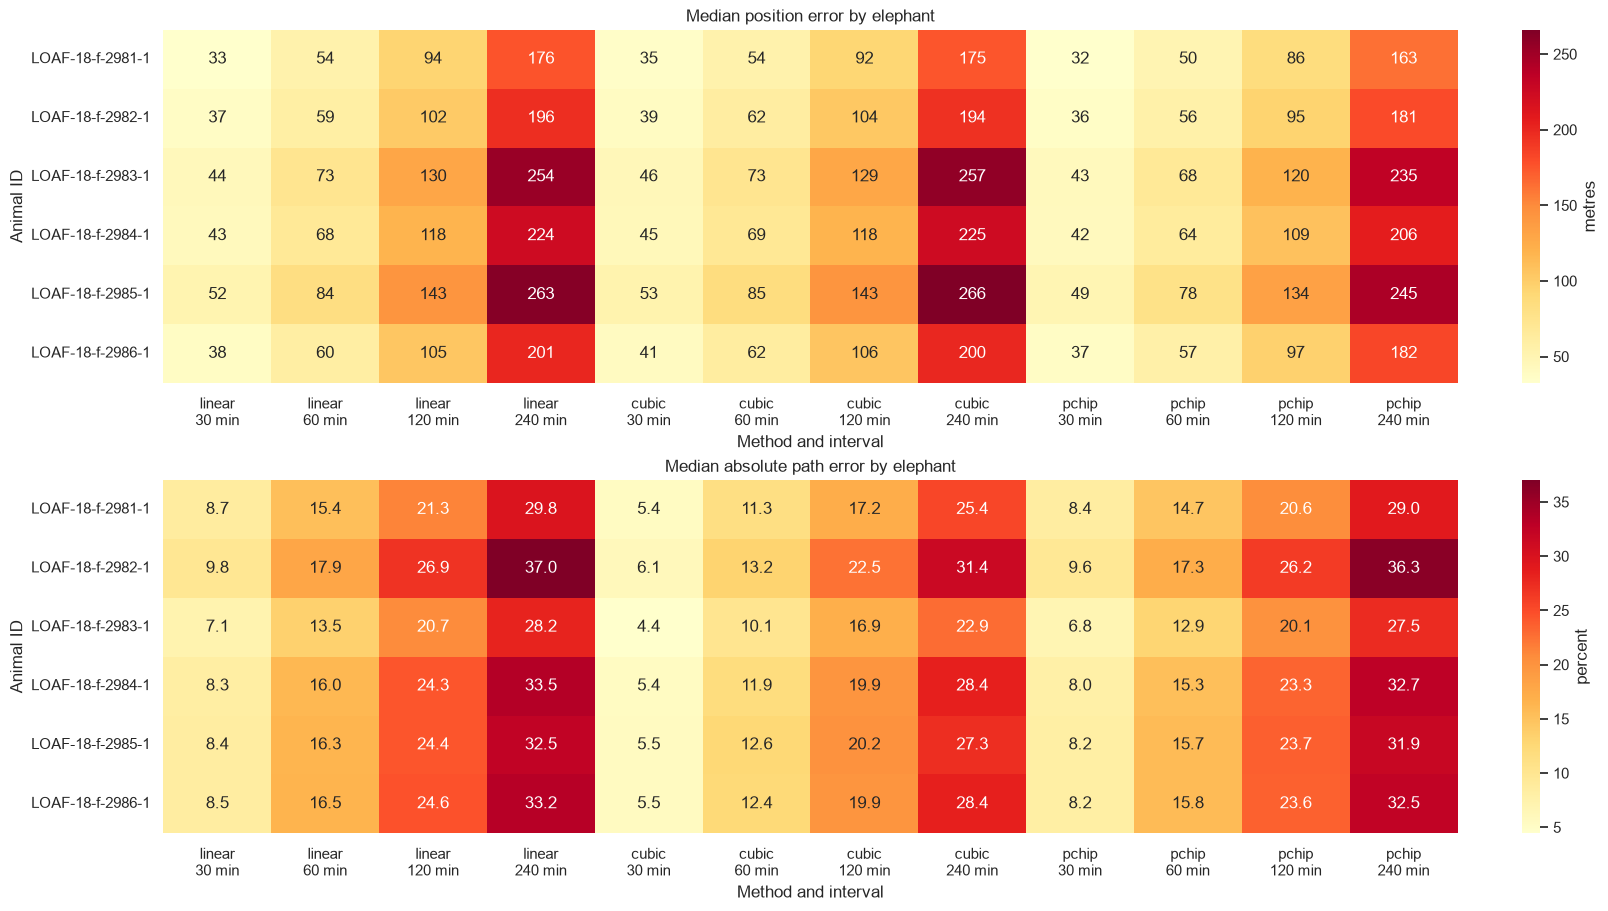

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week4_04_animal_variation.png


In [9]:
animal_plot = per_animal.copy()

animal_plot["MethodInterval"] = (
    animal_plot["Method"]
    + "\n"
    + animal_plot[
        "Interval_min"
    ]
    .astype(int)
    .astype(str)
    + " min"
)


ordered_columns = [
    f"{method}\n{interval} min"
    for method in method_order
    for interval in interval_order
]


position_pivot = (
    animal_plot.pivot(
        index="AnimalID",
        columns="MethodInterval",
        values="MedianPositionError_m",
    )
    .reindex(
        columns=ordered_columns
    )
)


path_pivot = (
    animal_plot.pivot(
        index="AnimalID",
        columns="MethodInterval",
        values=(
            "MedianAbsolutePathError_percent"
        ),
    )
    .reindex(
        columns=ordered_columns
    )
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(16, 9),
    constrained_layout=True,
)


sns.heatmap(
    position_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    ax=axes[0],
    cbar_kws={
        "label": "metres"
    },
)

axes[0].set(
    title="Median position error by elephant",
    xlabel="Method and interval",
    ylabel="Animal ID",
)


sns.heatmap(
    path_pivot,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    ax=axes[1],
    cbar_kws={
        "label": "percent"
    },
)

axes[1].set(
    title="Median absolute path error by elephant",
    xlabel="Method and interval",
    ylabel="Animal ID",
)


figure_path = (
    FIGURES_FOLDER
    / "week4_04_animal_variation.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

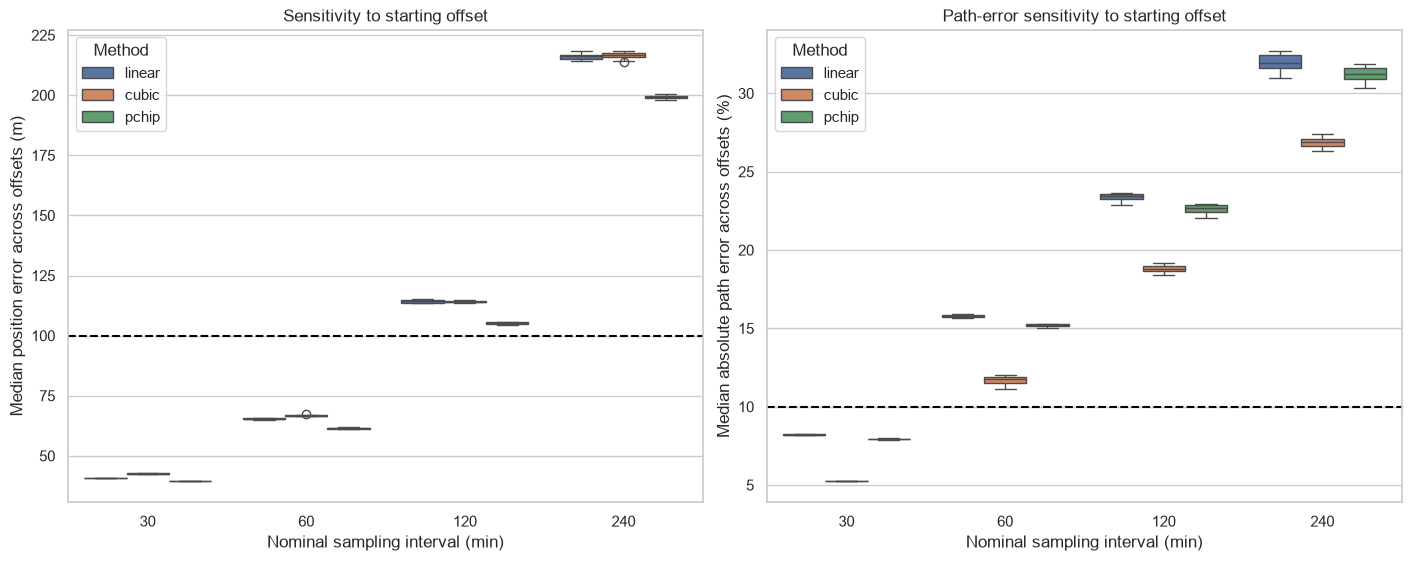

Saved: c:\Users\kookie\OneDrive\MMA3001_project\figures\week4_05_offset_variation.png


In [10]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.5),
    constrained_layout=True,
)


sns.boxplot(
    data=per_offset,
    x="Interval_min",
    y="MedianPositionError_m",
    hue="Method",
    hue_order=method_order,
    ax=axes[0],
)

axes[0].axhline(
    POSITION_TOLERANCE_M,
    color="black",
    linestyle="--",
)

axes[0].set(
    title="Sensitivity to starting offset",
    xlabel="Nominal sampling interval (min)",
    ylabel=(
        "Median position error "
        "across offsets (m)"
    ),
)


sns.boxplot(
    data=per_offset,
    x="Interval_min",
    y=(
        "MedianAbsolutePathError_percent"
    ),
    hue="Method",
    hue_order=method_order,
    ax=axes[1],
)

axes[1].axhline(
    PATH_TOLERANCE_PERCENT,
    color="black",
    linestyle="--",
)

axes[1].set(
    title="Path-error sensitivity to starting offset",
    xlabel="Nominal sampling interval (min)",
    ylabel=(
        "Median absolute path error "
        "across offsets (%)"
    ),
)


figure_path = (
    FIGURES_FOLDER
    / "week4_05_offset_variation.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved:", figure_path)

In [11]:
worst_cases = (
    cases.loc[
        cases["Status"].eq("ok")
    ]
    .nlargest(
        6,
        "P95Error_m",
    )
    .copy()
)


failure_columns = [
    "Method",
    "Interval_min",
    "Offset",
    "SegmentFixes",
    "RetainedAnchors",
    "EligibleWithheld",
    "MedianError_m",
    "P95Error_m",
    "MaxError_m",
    "SignedPathLengthError_percent",
    "AbsolutePathLengthError_percent",
    "CoordinateOvershootCount",
]


display(
    worst_cases[
        failure_columns
    ].round(3)
)


worst_cases[
    failure_columns
].to_csv(
    REPORTS_FOLDER
    / "week4_failure_case_summary.csv",
    index=False,
)

,Method,Interval_min,Offset,SegmentFixes,RetainedAnchors,EligibleWithheld,MedianError_m,P95Error_m,MaxError_m,SignedPathLengthError_percent,AbsolutePathLengthError_percent,CoordinateOvershootCount
3564,linear,240,10,83,5,60,515.725,3576.199,3964.276,-51.053,51.053,0
3563,linear,240,9,83,5,60,522.448,3438.815,3881.365,-57.270,57.270,0
3565,linear,240,11,83,5,60,453.508,3081.297,3571.890,-40.022,40.022,0
3562,linear,240,8,83,5,60,523.513,3073.445,3590.271,-66.494,66.494,0
5804,pchip,240,2,83,6,75,284.156,3014.987,3722.437,-20.554,20.554,0
4687,cubic,240,9,83,5,60,625.424,2988.171,3375.535,-55.761,55.761,20


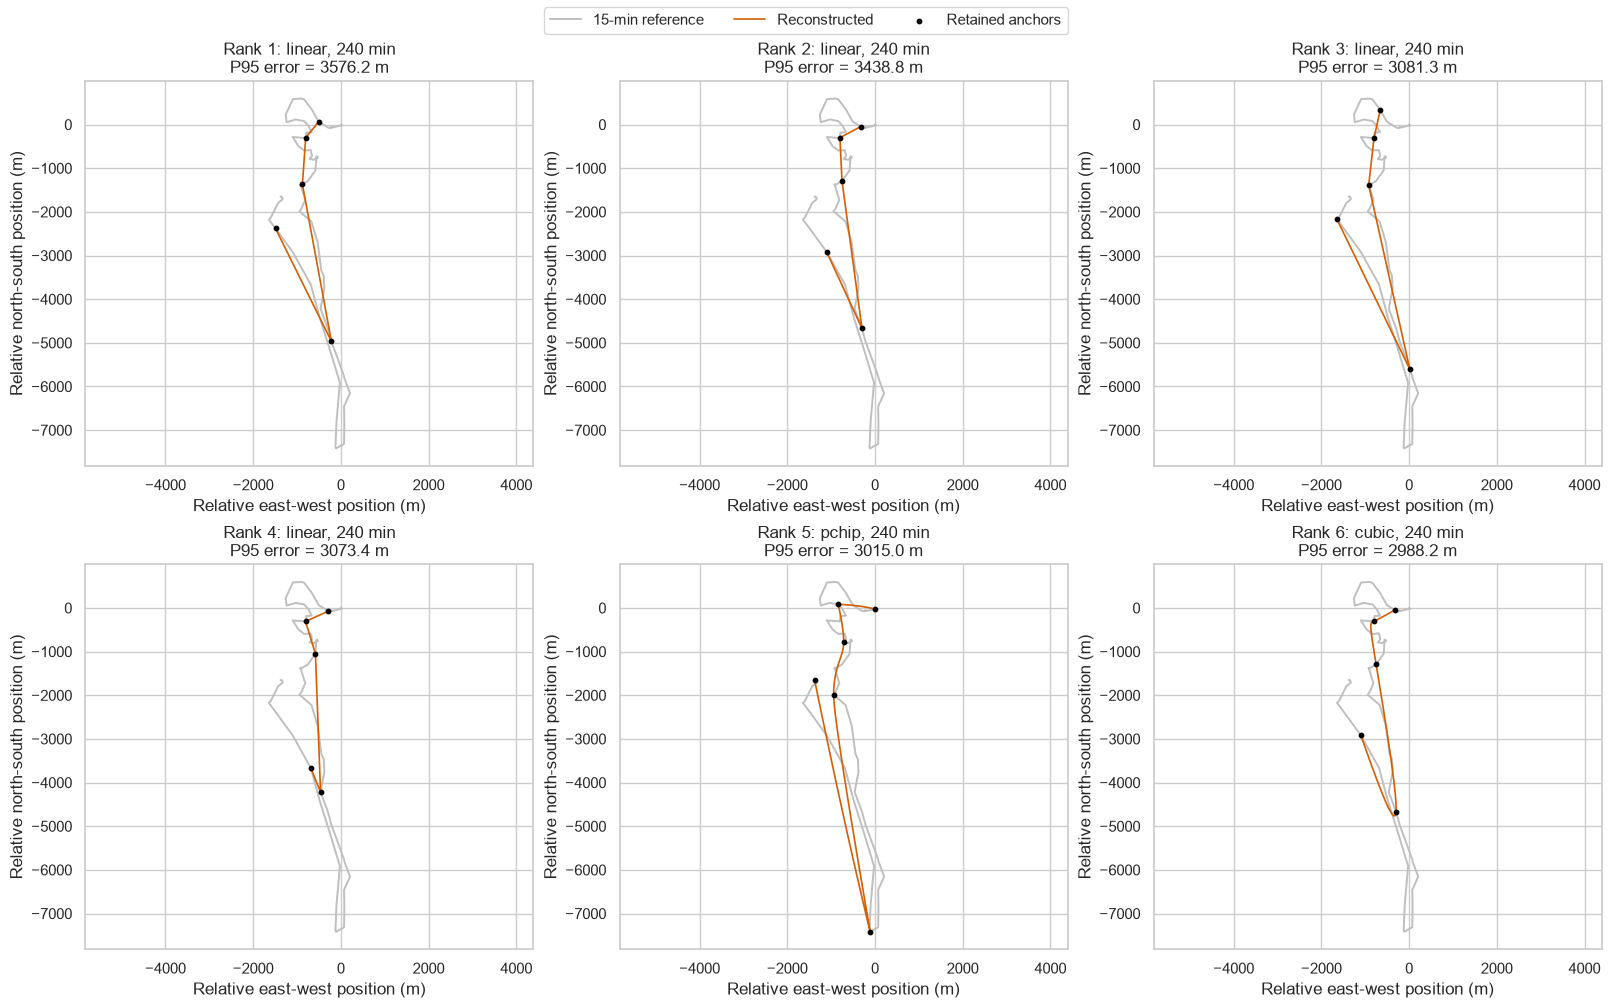

Saved privately: c:\Users\kookie\OneDrive\MMA3001_project\private_figures\week4_06_failure_case_gallery.png


In [12]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10),
    constrained_layout=True,
)


for number, (
    ax,
    row,
) in enumerate(
    zip(
        axes.flat,
        worst_cases.itertuples(
            index=False
        ),
    ),
    start=1,
):
    segment = (
        reference.loc[
            reference[
                "SegmentID"
            ].eq(row.SegmentID)
        ]
        .sort_values("Timestamp")
        .reset_index(drop=True)
    )

    mask = (
        reconstruction.make_downsampling_mask(
            segment,
            int(row.Interval_min),
            int(row.Offset),
        )
    )

    anchors = segment.loc[
        mask["Retained"].to_numpy()
    ].copy()

    predicted, _ = (
        reconstruction.reconstruct_case(
            reference,
            row.SegmentID,
            int(row.Interval_min),
            int(row.Offset),
            row.Method,
        )
    )

    combined = pd.concat(
        [
            anchors[
                [
                    "Timestamp",
                    "LocalX_m",
                    "LocalY_m",
                ]
            ].rename(
                columns={
                    "LocalX_m": "PlotX_m",
                    "LocalY_m": "PlotY_m",
                }
            ),
            predicted[
                [
                    "Timestamp",
                    "EstimatedX_m",
                    "EstimatedY_m",
                ]
            ].rename(
                columns={
                    "EstimatedX_m": "PlotX_m",
                    "EstimatedY_m": "PlotY_m",
                }
            ),
        ]
    ).sort_values("Timestamp")

    x_zero = float(
        segment["LocalX_m"].iloc[0]
    )

    y_zero = float(
        segment["LocalY_m"].iloc[0]
    )

    ax.plot(
        segment["LocalX_m"] - x_zero,
        segment["LocalY_m"] - y_zero,
        color="0.75",
        linewidth=1.4,
        label="15-min reference",
    )

    ax.plot(
        combined["PlotX_m"] - x_zero,
        combined["PlotY_m"] - y_zero,
        color="#D55E00",
        linewidth=1.2,
        label="Reconstructed",
    )

    ax.scatter(
        anchors["LocalX_m"] - x_zero,
        anchors["LocalY_m"] - y_zero,
        color="black",
        s=10,
        label="Retained anchors",
        zorder=5,
    )

    ax.set_title(
        f"Rank {number}: "
        f"{row.Method}, "
        f"{int(row.Interval_min)} min\n"
        f"P95 error = "
        f"{row.P95Error_m:.1f} m"
    )

    ax.set_xlabel(
        "Relative east-west position (m)"
    )

    ax.set_ylabel(
        "Relative north-south position (m)"
    )

    ax.axis("equal")


handles, labels = (
    axes.flat[0]
    .get_legend_handles_labels()
)

fig.legend(
    handles,
    labels,
    loc="outside upper center",
    ncol=3,
)


figure_path = (
    PRIVATE_FIGURES_FOLDER
    / "week4_06_failure_case_gallery.png"
)

fig.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("Saved privately:", figure_path)

In [13]:
interpretation_file = (
    REPORTS_FOLDER
    / "week4_failure_case_interpretation.md"
)


template = """# Week 4 failure-case interpretation

## Repeatable selection rule

The six displayed cases were selected as the successful common-eligible
cases with the largest case-level 95th-percentile position error.
They were not selected because they looked visually dramatic.

## My observations

### Movement geometry

Write what you observe about turns, stops, long movements or path shape here.

### Sampling interval and retained anchors

Write how the interval and anchor spacing contributed to the error here.

### Method behaviour

Write whether linear shortcutting, cubic overshoot or PCHIP shape behaviour
is visible here.

### Engineering implication

Write what these cases mean for the reliability of the final recommended
sampling interval here.

## Limitation

These are selected high-error cases from the available six-elephant dataset.
They do not prove that the same failure pattern occurs in all elephant
populations.
"""


if not interpretation_file.exists():
    interpretation_file.write_text(
        template,
        encoding="utf-8",
    )

print(
    "Open and complete this file:",
    interpretation_file,
)

Open and complete this file: c:\Users\kookie\OneDrive\MMA3001_project\reports\week4_failure_case_interpretation.md


In [14]:
acceptable_candidates = (
    decision_table.loc[
        decision_table[
            "MandatoryCriteriaPass"
        ].eq(True)
    ]
    [
        [
            "Method",
            "Interval_min",
            "MedianPositionError_m",
            "P95PositionError_m",
            "MedianAbsolutePathError_percent",
            "MedianSignedPathError_percent",
            "MedianFixReduction_percent",
            "OvershootPercent",
            "CaseCoverage_percent",
            "AnimalsPassingBoth",
            "AnimalsEvaluated",
            "AllAnimalsPass",
            "TotalInterpolationRuntime_s",
        ]
    ]
    .sort_values(
        [
            "Interval_min",
            "Method",
        ],
        ascending=[
            False,
            True,
        ],
    )
    .reset_index(drop=True)
)


display(
    acceptable_candidates.round(3)
)


if acceptable_candidates.empty:
    print(
        "No method-interval combination "
        "passed both mandatory criteria."
    )
else:
    longest_passing_interval = int(
        acceptable_candidates[
            "Interval_min"
        ].max()
    )

    print(
        "Longest interval with at least "
        "one overall pass:",
        longest_passing_interval,
        "minutes",
    )

,Method,Interval_min,MedianPositionError_m,P95PositionError_m,MedianAbsolutePathError_percent,MedianSignedPathError_percent,MedianFixReduction_percent,OvershootPercent,CaseCoverage_percent,AnimalsPassingBoth,AnimalsEvaluated,AllAnimalsPass,TotalInterpolationRuntime_s
0,cubic,30,42.615,160.256,5.275,-5.275,49.894,32.696,94.805,6,6,True,0.094
1,linear,30,40.786,166.767,8.180,-8.180,49.894,0.000,97.403,6,6,True,0.016
2,pchip,30,39.632,158.135,7.907,-7.907,49.894,0.000,97.403,6,6,True,0.105


Longest interval with at least one overall pass: 30 minutes


In [15]:
# STOP AND ENTER YOUR PERSONAL D7 DECISION.

FINAL_METHOD = "pchip"

FINAL_INTERVAL_MIN = 30

DECISION_REASON = """
I chose 30 minute intervals as it passed all the tests needed unlike the 60,120 and 240 minute intervals which failed the mandatory criteria. The pchip method was chosen as it had the lowest median position error and median absolute path error compared to the other methods.
""".strip()

EVIDENCE_THAT_WOULD_CHANGE_DECISION = """
Id make it a smaller interval than 30 if it shwoed that 30 missed important movements but it didnt seem to miss any important movements and the 30 minute interval was the only one that passed all the mandatory criteria.
""".strip()


assert FINAL_METHOD in method_order, (
    "Enter linear, cubic or pchip."
)

assert FINAL_INTERVAL_MIN in interval_order, (
    "Enter 30, 60, 120 or 240."
)

assert len(DECISION_REASON) >= 80, (
    "Explain the decision in your own words."
)

assert (
    len(
        EVIDENCE_THAT_WOULD_CHANGE_DECISION
    )
    >= 40
), (
    "State what evidence would change the decision."
)


selected_rows = decision_table.loc[
    decision_table["Method"].eq(
        FINAL_METHOD
    )
    & decision_table[
        "Interval_min"
    ].eq(
        FINAL_INTERVAL_MIN
    )
]


assert len(selected_rows) == 1

selected = selected_rows.iloc[0]


assert bool(
    selected["MandatoryCriteriaPass"]
), (
    "The selected option does not pass both "
    "frozen mandatory criteria. If you still "
    "intend to select it, stop and justify a "
    "formal change to D6 first."
)


final_decision = {
    "decision": "D7",
    "recorded_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "selected_method": FINAL_METHOD,
    "selected_interval_minutes": int(
        FINAL_INTERVAL_MIN
    ),
    "median_position_error_m": float(
        selected[
            "MedianPositionError_m"
        ]
    ),
    "p95_position_error_m": float(
        selected[
            "P95PositionError_m"
        ]
    ),
    "median_absolute_path_error_percent": float(
        selected[
            "MedianAbsolutePathError_percent"
        ]
    ),
    "median_fix_reduction_percent": float(
        selected[
            "MedianFixReduction_percent"
        ]
    ),
    "overshoot_percent": float(
        selected[
            "OvershootPercent"
        ]
    ),
    "animals_passing_both": int(
        selected[
            "AnimalsPassingBoth"
        ]
    ),
    "animals_evaluated": int(
        selected[
            "AnimalsEvaluated"
        ]
    ),
    "all_animals_pass": bool(
        selected[
            "AllAnimalsPass"
        ]
    ),
    "reason": DECISION_REASON,
    "evidence_that_would_change_decision": (
        EVIDENCE_THAT_WOULD_CHANGE_DECISION
    ),
}


decision_file = (
    REPORTS_FOLDER
    / "week4_final_decision.yaml"
)


with decision_file.open(
    "w",
    encoding="utf-8",
) as stream:
    yaml.safe_dump(
        final_decision,
        stream,
        sort_keys=False,
    )


with CONTRACT_FILE.open(
    "r",
    encoding="utf-8",
) as stream:
    contract = yaml.safe_load(stream)


contract["final_decision"] = {
    "method": FINAL_METHOD,
    "interval_minutes": int(
        FINAL_INTERVAL_MIN
    ),
    "decision_record": (
        "reports/week4_final_decision.yaml"
    ),
}


with CONTRACT_FILE.open(
    "w",
    encoding="utf-8",
) as stream:
    yaml.safe_dump(
        contract,
        stream,
        sort_keys=False,
    )


print("D7 SAVED")
print(
    "Selected method:",
    FINAL_METHOD,
)
print(
    "Selected interval:",
    FINAL_INTERVAL_MIN,
    "minutes",
)
print(
    "Median position error:",
    round(
        selected[
            "MedianPositionError_m"
        ],
        3,
    ),
    "m",
)
print(
    "Median absolute path error:",
    round(
        selected[
            "MedianAbsolutePathError_percent"
        ],
        3,
    ),
    "%",
)
print(
    "Median fix reduction:",
    round(
        selected[
            "MedianFixReduction_percent"
        ],
        3,
    ),
    "%",
)
print(
    "Animals passing both:",
    int(
        selected[
            "AnimalsPassingBoth"
        ]
    ),
    "/",
    int(
        selected[
            "AnimalsEvaluated"
        ]
    ),
)

D7 SAVED
Selected method: pchip
Selected interval: 30 minutes
Median position error: 39.632 m
Median absolute path error: 7.907 %
Median fix reduction: 49.894 %
Animals passing both: 6 / 6
